In [1]:
!nvidia-smi


Sun Nov 15 17:10:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.01              KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4080        On  |   00000000:01:00.0  On |                  N/A |
|  0%   41C    P8             13W /  320W |    1180MiB /  16376MiB |     17%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from numba import cuda, float64, int64
from numba.cuda.random import create_xoroshiro128p_states
from numba.cuda.random import xoroshiro128p_normal_float32
from numba.cuda.random import xoroshiro128p_uniform_float32

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import time


In [3]:
L = 64
N = L * L
J = 1.0

q0 = np.pi / 4
D = J * np.tan(q0)
J2 = J / (4 * np.cos(q0))

B_z = 0.0

replicas = 32
adapt_every = 500
sample_every = 1000

seed_dmi = 2026
seed_frustration = 2027

n_therm = 500000
n_measure = 1000000

sigma_initial = 0.6
T = np.linspace(3, 0.1, 100)


In [4]:
def random_spin_field():
    spins = np.random.normal(size=(L, L, 3))
    spins /= np.linalg.norm(spins, axis=2, keepdims=True)
    return spins

lattice = random_spin_field()

print(lattice.shape)


(64, 64, 3)


In [5]:
def delta_energy_dmi(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]

    nn = (
        lattice[(x + 1) % L, y]
        + lattice[(x - 1) % L, y]
        + lattice[x, (y + 1) % L]
        + lattice[x, (y - 1) % L]
    )

    old_spin = lattice[x, y]
    delta_spin = trial_spin - old_spin

    E_exchange = -J * np.dot(delta_spin, nn)

    E_dmi = -D * np.dot(
        delta_spin,
        np.cross(
            lattice[(x + 1) % L, y] - lattice[(x - 1) % L, y],
            [1, 0, 0]
        )
    )

    E_field = -B_z * delta_spin[2]

    return E_exchange + E_dmi + E_field

def delta_energy_frustration(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]

    nn = (
        lattice[(x + 1) % L, y]
        + lattice[(x - 1) % L, y]
        + lattice[x, (y + 1) % L]
        + lattice[x, (y - 1) % L]
    )

    nnn = (
        lattice[(x + 2) % L, y]
        + lattice[(x - 2) % L, y]
    )

    old_spin = lattice[x, y]
    delta_spin = trial_spin - old_spin

    E_exchange = -J * np.dot(delta_spin, nn)
    E_frustration = J2 * np.dot(delta_spin, nnn)
    E_field = -B_z * delta_spin[2]

    return E_exchange + E_frustration + E_field


In [6]:
def total_energy_dmi(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            E += -J * np.dot(
                lattice[x, y],
                lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            )

            E += D * np.dot(
                lattice[x, y],
                np.cross([1, 0, 0], lattice[(x + 1) % nx, y])
            )

            E -= B_z * lattice[x, y, 2]

    return E

def total_energy_frustration(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            nn = lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            nnn = lattice[(x + 2) % nx, y]

            E += -J * np.dot(lattice[x, y], nn)
            E += J2 * np.dot(lattice[x, y], nnn)
            E -= B_z * lattice[x, y, 2]

    return E


In [7]:
@cuda.jit
def gpu_sweeps(spins, counts, rng_states, temp, d_sigma, B_z, model_id, J, J2, D, sweeps):

    replica = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    n_per_color = (nx // 4) * (ny // 2)
    rid = replica * n_per_color + tid

    sigma = d_sigma[0]
    accepted = 0

    for sweep in range(sweeps):
        for color in range(8):

            cx = color // 2
            cy = color % 2

            x = 4 * (tid // (ny // 2)) + cx
            y = 2 * (tid % (ny // 2)) + cy

            xp = (x + 1) % nx
            xm = (x - 1) % nx
            yp = (y + 1) % ny
            ym = (y - 1) % ny

            old_x = spins[replica, x, y, 0]
            old_y = spins[replica, x, y, 1]
            old_z = spins[replica, x, y, 2]

            tx = old_x + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            ty = old_y + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            tz = old_z + sigma * xoroshiro128p_normal_float32(rng_states, rid)

            norm = math.sqrt(tx*tx + ty*ty + tz*tz)

            if norm > 0.0:
                tx /= norm
                ty /= norm
                tz /= norm

                dx = tx - old_x
                dy = ty - old_y
                dz = tz - old_z

                n0 = (
                    spins[replica, xp, y, 0]
                    + spins[replica, xm, y, 0]
                    + spins[replica, x, yp, 0]
                    + spins[replica, x, ym, 0]
                )

                n1 = (
                    spins[replica, xp, y, 1]
                    + spins[replica, xm, y, 1]
                    + spins[replica, x, yp, 1]
                    + spins[replica, x, ym, 1]
                )

                n2 = (
                    spins[replica, xp, y, 2]
                    + spins[replica, xm, y, 2]
                    + spins[replica, x, yp, 2]
                    + spins[replica, x, ym, 2]
                )

                dE = -J * (dx*n0 + dy*n1 + dz*n2) - B_z*dz

                if model_id == 1:
                    xpp = (x + 2) % nx
                    xmm = (x - 2) % nx

                    dE += J2 * (
                        dx * (
                            spins[replica, xpp, y, 0]
                            + spins[replica, xmm, y, 0]
                        )
                        + dy * (
                            spins[replica, xpp, y, 1]
                            + spins[replica, xmm, y, 1]
                        )
                        + dz * (
                            spins[replica, xpp, y, 2]
                            + spins[replica, xmm, y, 2]
                        )
                    )

                else:

                    ax1 = (
                        spins[replica, xp, y, 2]
                        - spins[replica, xm, y, 2]
                    )

                    ax2 = -(
                        spins[replica, xp, y, 1]
                        - spins[replica, xm, y, 1]
                    )

                    dE -= D * (dy*ax1 + dz*ax2)

                if dE <= 0.0 or (
                    temp > 0.0 and
                    xoroshiro128p_uniform_float32(rng_states, rid) < math.exp(-dE/temp)
                ):
                    spins[replica, x, y, 0] = tx
                    spins[replica, x, y, 1] = ty
                    spins[replica, x, y, 2] = tz
                    accepted += 1

            cuda.syncthreads()

    counts[replica, tid] = accepted


In [8]:
@cuda.jit
def measure_gpu(spins, energies, magnetizations, B_z, model_id, J, J2, D):

    r = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    sh_e = cuda.shared.array(256, dtype=float64)
    sh_mx = cuda.shared.array(256, dtype=float64)
    sh_my = cuda.shared.array(256, dtype=float64)
    sh_mz = cuda.shared.array(256, dtype=float64)

    e = 0.0
    mx = 0.0
    my = 0.0
    mz = 0.0

    for k in range(tid, nx * ny, cuda.blockDim.x):
        x = k // ny
        y = k % ny

        xp = (x + 1) % nx
        yp = (y + 1) % ny

        sx = float64(spins[r, x, y, 0])
        sy = float64(spins[r, x, y, 1])
        sz = float64(spins[r, x, y, 2])

        ax = float64(spins[r, xp, y, 0])
        ay = float64(spins[r, xp, y, 1])
        az = float64(spins[r, xp, y, 2])

        bx = float64(spins[r, x, yp, 0])
        by = float64(spins[r, x, yp, 1])
        bz = float64(spins[r, x, yp, 2])

        e -= J * (
            sx * (ax + bx)
            + sy * (ay + by)
            + sz * (az + bz)
        )

        e -= B_z * sz

        if model_id == 1:
            xpp = (x + 2) % nx

            e += J2 * (
                sx * float64(spins[r, xpp, y, 0])
                + sy * float64(spins[r, xpp, y, 1])
                + sz * float64(spins[r, xpp, y, 2])
            )

        else:
            e -= D * (sy * az - sz * ay)

        mx += sx
        my += sy
        mz += sz

    sh_e[tid] = e
    sh_mx[tid] = mx
    sh_my[tid] = my
    sh_mz[tid] = mz

    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            sh_e[tid] += sh_e[tid + stride]
            sh_mx[tid] += sh_mx[tid + stride]
            sh_my[tid] += sh_my[tid + stride]
            sh_mz[tid] += sh_mz[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        energies[r] = sh_e[0]
        magnetizations[r, 0] = sh_mx[0]
        magnetizations[r, 1] = sh_my[0]
        magnetizations[r, 2] = sh_mz[0]


In [9]:
@cuda.jit
def adapt_sigma_gpu(counts, d_sigma, N, sweeps):

    tid = cuda.threadIdx.x
    ncols = counts.shape[1]
    total = 0

    for i in range(tid, counts.shape[0] * ncols, 256):
        total += counts[i // ncols, i % ncols]

    sh = cuda.shared.array(256, dtype=int64)
    sh[tid] = total

    cuda.syncthreads()

    stride = 128

    while stride > 0:
        if tid < stride:
            sh[tid] += sh[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        R = sh[0] / (counts.shape[0] * N * sweeps)
        sigma = d_sigma[0] * math.exp(0.5 * (R - 0.5))
        d_sigma[0] = min(max(sigma, 1e-3), 2.0)


In [10]:
@cuda.jit
def accumulate_stats_gpu(d_energies, d_magnetizations, counts, stats):

    r = cuda.grid(1)

    if r < d_energies.shape[0]:
        n = stats[r, 0] + 1.0

        E = d_energies[r]

        delta_E = E - stats[r, 1]
        E_mean = stats[r, 1] + delta_E / n

        stats[r, 2] += delta_E * (E - E_mean)
        stats[r, 1] = E_mean

        mx = d_magnetizations[r, 0]
        my = d_magnetizations[r, 1]
        mz = d_magnetizations[r, 2]

        M_abs = math.sqrt(mx*mx + my*my + mz*mz)

        delta_M = M_abs - stats[r, 3]
        M_abs_mean = stats[r, 3] + delta_M / n

        stats[r, 4] += delta_M * (M_abs - M_abs_mean)
        stats[r, 3] = M_abs_mean
        stats[r, 0] = n

        accepted = 0

        for k in range(counts.shape[1]):
            accepted += counts[r, k]

        stats[r, 5] += accepted


In [11]:
@cuda.jit
def finalize_stats_gpu(stats, d_sigma, result, temp, N, n_measure):

    if cuda.grid(1) == 0:
        n_total = 0.0

        E_mean = 0.0
        E_m2 = 0.0

        M_abs_mean = 0.0
        M_m2 = 0.0

        accepted_sum = 0.0

        for r in range(stats.shape[0]):
            n = stats[r, 0]
            new_total = n_total + n

            delta_E = stats[r, 1] - E_mean
            delta_M = stats[r, 3] - M_abs_mean

            E_m2 += (
                stats[r, 2]
                + delta_E * delta_E * n_total * n / new_total
            )

            M_m2 += (
                stats[r, 4]
                + delta_M * delta_M * n_total * n / new_total
            )

            E_mean += delta_E * n / new_total
            M_abs_mean += delta_M * n / new_total

            n_total = new_total
            accepted_sum += stats[r, 5]

        result[0] = E_m2 / (n_total * N * temp ** 2)
        result[1] = M_m2 / (n_total * N * temp)
        result[2] = M_abs_mean
        result[3] = E_mean
        result[4] = accepted_sum / (stats.shape[0] * N * n_measure)
        result[5] = d_sigma[0]


In [12]:
def simulate_temp(lattice, T, B_z, model, replicas, adapt_every, sample_every, seed, n_therm_run, n_measure_run, sigma_initial):

    model_id = 0 if model == "dmi" else 1

    nx, ny = lattice.shape[:2]
    N = nx * ny
    n_per_color = (nx // 4) * (ny // 2)

    rng = np.random.default_rng(seed)
    batch = rng.normal(size=(replicas, nx, ny, 3)).astype(np.float32)
    batch /= np.linalg.norm(batch, axis=3, keepdims=True)
    batch[0] = lattice.astype(np.float32)

    d_spins = cuda.to_device(batch)
    d_counts = cuda.device_array((replicas, n_per_color), dtype=np.int32)
    d_energies = cuda.device_array(replicas, dtype=np.float64)
    d_magnetizations = cuda.device_array((replicas, 3), dtype=np.float64)
    d_sigma = cuda.to_device(np.array([sigma_initial], dtype=np.float32))
    d_stats = cuda.device_array((replicas, 6), dtype=np.float64)
    d_result = cuda.device_array(6, dtype=np.float64)

    rng_states = create_xoroshiro128p_states(
        replicas * n_per_color, seed=seed
    )

    J_gpu = np.float32(J)
    J2_gpu = np.float32(J2)
    D_gpu = np.float32(D)
    B_gpu = np.float32(B_z)

    stats_zero = np.zeros((replicas, 6), dtype=np.float64)
    sigma_start = np.array([sigma_initial], dtype=np.float32)

    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []

    for t in T:
        start_time = time.perf_counter()
        temp = np.float32(t)

        d_stats.copy_to_device(stats_zero)
        d_sigma.copy_to_device(sigma_start)

        for start in range(0, n_therm_run, adapt_every):
            steps = min(adapt_every, n_therm_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                temp, d_sigma, B_gpu,
                model_id, J_gpu, J2_gpu, D_gpu, steps
            )

            adapt_sigma_gpu[1, 256](
                d_counts, d_sigma, N, steps
            )

        for start in range(0, n_measure_run, sample_every):
            steps = min(sample_every, n_measure_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                temp, d_sigma, B_gpu,
                model_id, J_gpu, J2_gpu, D_gpu, steps
            )

            measure_gpu[replicas, 256](
                d_spins, d_energies, d_magnetizations,
                B_gpu, model_id, J_gpu, J2_gpu, D_gpu
            )

            accumulate_stats_gpu[(replicas + 127) // 128, 128](
                d_energies, d_magnetizations,
                d_counts, d_stats
            )

        finalize_stats_gpu[1, 1](
            d_stats, d_sigma, d_result,
            temp, N, n_measure_run
        )

        c, Kai, M_abs_mean, E_mean, R_mean, sigma = d_result.copy_to_host()

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(R_mean)
        sigma_vs_t.append(sigma)

        elapsed_time = time.perf_counter() - start_time

        print(
            f"{model} | T={t:.4f} | Time={elapsed_time:.2f} s | "
            f"E/N={E_mean/N:.4f} | M/N={M_abs_mean/N:.4f} | "
            f"C={c:.4f} | Chi={Kai:.4f} | "
            f"R={R_mean:.4f} | Sigma={sigma:.4f}",
            flush=True
        )

        np.savez(
            f"progress_{model}.npz",
            T=np.asarray(T[:len(c_vs_t)]),
            C=np.asarray(c_vs_t),
            Kai=np.asarray(kai_vs_t),
            M=np.asarray(m_vs_t),
            E=np.asarray(e_vs_t),
            R=np.asarray(r_vs_t),
            Sigma=np.asarray(sigma_vs_t)
        )

        np.save(
            f"spins_{model}_latest.npy",
            d_spins.copy_to_host()
        )

    return (
        np.array(c_vs_t),
        np.array(kai_vs_t),
        np.array(m_vs_t),
        np.array(e_vs_t),
        np.array(r_vs_t),
        np.array(sigma_vs_t)
    )


In [13]:
spin_test = random_spin_field().astype(np.float32)
rng_test = np.random.default_rng(5)
x, y = 7, 11
trial = spin_test[x, y] + 0.3 * rng_test.normal(size=3)
trial /= np.linalg.norm(trial)

E_old = total_energy_dmi(spin_test, B_z)
dE = delta_energy_dmi(spin_test, x, y, trial, B_z)
spin_trial = spin_test.copy()
spin_trial[x, y] = trial
E_new = total_energy_dmi(spin_trial, B_z)

print("ΔE local vs total:", dE, E_new - E_old)
assert np.isclose(dE, E_new - E_old, atol=1e-4)

d_batch = cuda.to_device(spin_test[None])
d_energies = cuda.device_array(1, dtype=np.float64)
d_magnetizations = cuda.device_array((1, 3), dtype=np.float64)
measure_gpu[1, 256](
    d_batch, d_energies, d_magnetizations,
    np.float32(B_z), 0, np.float32(J), np.float32(J2), np.float32(D)
)
E_gpu = d_energies.copy_to_host()[0]
print("GPU vs CPU total energy:", E_gpu, E_old)
assert np.isclose(E_gpu, E_old, atol=1e-3)
print("Energy consistency: PASS")


ΔE local vs total: 0.5823132766649035 0.5823132906936195


/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


GPU vs CPU total energy: 70.73598988278636 70.73598746937087
Energy consistency: PASS


In [14]:
from pathlib import Path
import os

T_cal = np.linspace(3.0, 0.1, 20)
cal_folder = Path("calibration_dmi_x").resolve()
cal_folder.mkdir(exist_ok=True)

original_folder = Path.cwd()
try:
    os.chdir(cal_folder)

    c_vs_t_dmi_cal, kai_vs_t_dmi_cal, m_vs_t_dmi_cal, e_vs_t_dmi_cal, r_vs_t_dmi_cal, sigma_vs_t_dmi_cal = simulate_temp(
        lattice, T_cal, B_z, "dmi",
        replicas, adapt_every, sample_every,
        seed_dmi, 20000, 20000, sigma_initial
    )
finally:
    os.chdir(original_folder)

print("Calibration folder:", cal_folder)


/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packa

dmi | T=3.0000 | Time=1.94 s | E/N=-0.3024 | M/N=0.0185 | C=0.1074 | Chi=0.0814 | R=0.8004 | Sigma=2.0000
dmi | T=2.8474 | Time=1.06 s | E/N=-0.3199 | M/N=0.0183 | C=0.1160 | Chi=0.0820 | R=0.7898 | Sigma=2.0000
dmi | T=2.6947 | Time=1.05 s | E/N=-0.3395 | M/N=0.0183 | C=0.1363 | Chi=0.0894 | R=0.7780 | Sigma=2.0000
dmi | T=2.5421 | Time=1.05 s | E/N=-0.3609 | M/N=0.0194 | C=0.1557 | Chi=0.1034 | R=0.7648 | Sigma=2.0000
dmi | T=2.3895 | Time=1.05 s | E/N=-0.3856 | M/N=0.0190 | C=0.1715 | Chi=0.1140 | R=0.7501 | Sigma=2.0000
dmi | T=2.2368 | Time=1.05 s | E/N=-0.4146 | M/N=0.0200 | C=0.2196 | Chi=0.1199 | R=0.7332 | Sigma=2.0000
dmi | T=2.0842 | Time=1.05 s | E/N=-0.4461 | M/N=0.0203 | C=0.2248 | Chi=0.1448 | R=0.7140 | Sigma=2.0000
dmi | T=1.9316 | Time=1.05 s | E/N=-0.4858 | M/N=0.0211 | C=0.2743 | Chi=0.1812 | R=0.6919 | Sigma=2.0000
dmi | T=1.7789 | Time=1.04 s | E/N=-0.5314 | M/N=0.0217 | C=0.3369 | Chi=0.1884 | R=0.6661 | Sigma=2.0000
dmi | T=1.6263 | Time=1.04 s | E/N=-0.5881 | M

DMI-x measured peak: -0.7853981633974483 0.0
Target magnitude qx: 0.7853981633974483
FFT resolution: 0.09817477042468103


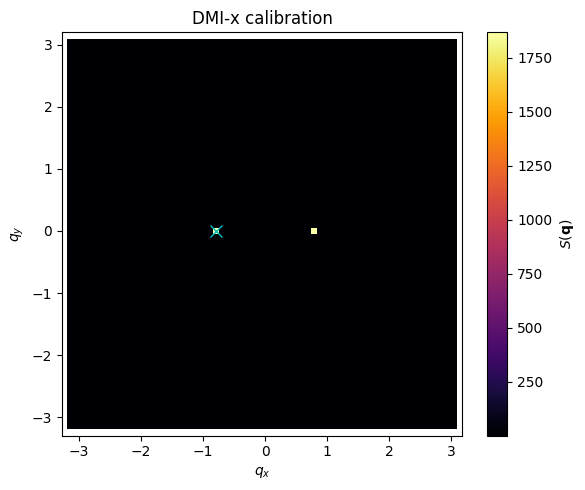

In [15]:
def static_structure_factor(spins):
    replicas, nx, ny, _ = spins.shape
    N = nx * ny
    S_fft = np.fft.fft2(spins, axes=(1, 2))
    S_q = np.mean(np.sum(np.abs(S_fft)**2, axis=3), axis=0) / N
    S_q = np.fft.fftshift(S_q)
    qx = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(ny))
    return qx, qy, S_q

spins_dmi_new = np.load(cal_folder / "spins_dmi_latest.npy")
qx, qy, S_q = static_structure_factor(spins_dmi_new)
S_peak = S_q.copy()
S_peak[len(qx)//2, len(qy)//2] = 0
i, j = np.unravel_index(np.argmax(S_peak), S_peak.shape)

print("DMI-x measured peak:", qx[i], qy[j])
print("Target magnitude qx:", np.pi/4)
print("FFT resolution:", 2*np.pi/L)

plt.figure(figsize=(6, 5))
plt.pcolormesh(qx, qy, S_q.T, shading="auto", cmap="inferno")
plt.plot(qx[i], qy[j], "cx", markersize=9)
plt.xlabel(r"$q_x$")
plt.ylabel(r"$q_y$")
plt.colorbar(label=r"$S(\mathbf{q})$")
plt.title("DMI-x calibration")
plt.axis("equal")
plt.tight_layout()
plt.show()


In [17]:
RUN_PRODUCTION = True

if RUN_PRODUCTION:
    prod_folder = Path("production_dmi_x").resolve()
    prod_folder.mkdir(exist_ok=True)

    original_folder = Path.cwd()
    try:
        os.chdir(prod_folder)

        c_vs_t_dmi, kai_vs_t_dmi, m_vs_t_dmi, e_vs_t_dmi, r_vs_t_dmi, sigma_vs_t_dmi = simulate_temp(
            lattice, T, B_z, "dmi",
            replicas, adapt_every, sample_every,
            seed_dmi, n_therm, n_measure, sigma_initial
        )
    finally:
        os.chdir(original_folder)

    print("Production saved in:", prod_folder)


dmi | T=3.0000 | Time=39.14 s | E/N=-0.3027 | M/N=0.0183 | C=0.1061 | Chi=0.0810 | R=0.8004 | Sigma=2.0000
dmi | T=2.9707 | Time=38.15 s | E/N=-0.3060 | M/N=0.0183 | C=0.1068 | Chi=0.0816 | R=0.7985 | Sigma=2.0000
dmi | T=2.9414 | Time=37.98 s | E/N=-0.3091 | M/N=0.0184 | C=0.1090 | Chi=0.0827 | R=0.7965 | Sigma=2.0000
dmi | T=2.9121 | Time=38.00 s | E/N=-0.3123 | M/N=0.0185 | C=0.1106 | Chi=0.0860 | R=0.7945 | Sigma=2.0000
dmi | T=2.8828 | Time=38.10 s | E/N=-0.3157 | M/N=0.0185 | C=0.1142 | Chi=0.0873 | R=0.7924 | Sigma=2.0000
dmi | T=2.8535 | Time=38.13 s | E/N=-0.3193 | M/N=0.0186 | C=0.1180 | Chi=0.0883 | R=0.7903 | Sigma=2.0000
dmi | T=2.8242 | Time=38.12 s | E/N=-0.3226 | M/N=0.0186 | C=0.1191 | Chi=0.0888 | R=0.7881 | Sigma=2.0000
dmi | T=2.7949 | Time=38.12 s | E/N=-0.3261 | M/N=0.0186 | C=0.1233 | Chi=0.0914 | R=0.7859 | Sigma=2.0000
dmi | T=2.7657 | Time=38.13 s | E/N=-0.3299 | M/N=0.0187 | C=0.1241 | Chi=0.0916 | R=0.7837 | Sigma=2.0000
dmi | T=2.7364 | Time=38.12 s | E/N=-

In [18]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

folder = Path("production_dmi_x")

data_dmi = np.load(folder / "progress_dmi.npz")
spins_dmi = np.load(folder / "spins_dmi_latest.npy")

print("Temperatures:", len(data_dmi["T"]))
print("Last temperature:", data_dmi["T"][-1])
print("Spin shape:", spins_dmi.shape)
print("Last energy:", data_dmi["E"][-1])


Temperatures: 100
Last temperature: 0.1
Spin shape: (32, 64, 64, 3)
Last energy: -2.313116909215986


DMI-x production wavevector:
qx = -0.7853981633974483
qy = 0.0
|q| = 0.7853981633974483
Wavelength = 8.0


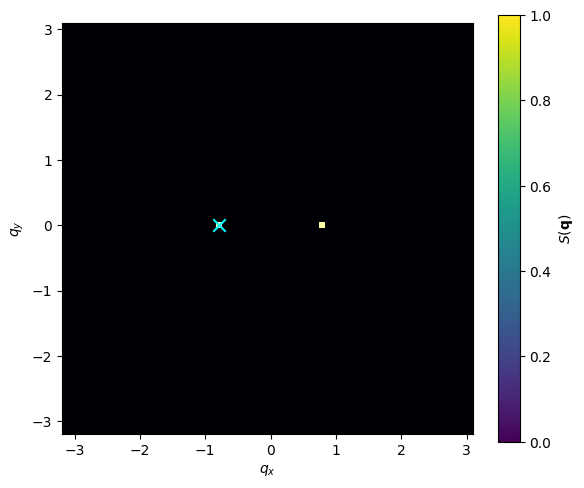

In [19]:

def static_structure_factor(spins):
    nx, ny = spins.shape[1:3]
    N = nx * ny

    S_fft = np.fft.fft2(spins, axes=(1, 2))

    S_q = np.mean(
        np.sum(np.abs(S_fft) ** 2, axis=3),
        axis=0
    ) / N

    S_q = np.fft.fftshift(S_q)

    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

    return qx, qy, S_q


qx, qy, S_q = static_structure_factor(spins_dmi)

S_peak = S_q.copy()
S_peak[len(qx)//2, len(qy)//2] = 0

i, j = np.unravel_index(np.argmax(S_peak), S_peak.shape)

print("DMI-x production wavevector:")
print("qx =", qx[i])
print("qy =", qy[j])
print("|q| =", np.hypot(qx[i], qy[j]))
print("Wavelength =", 2 * np.pi / np.hypot(qx[i], qy[j]))

plt.figure(figsize=(6, 5))
plt.pcolormesh(qx, qy, S_q.T, shading="auto", cmap="inferno")
plt.scatter(qx[i], qy[j], marker="x", color="cyan", s=80)
plt.xlabel(r"$q_x$")
plt.ylabel(r"$q_y$")
plt.colorbar(label=r"$S(\mathbf{q})$")
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()


DMI-x: -0.7853981633974483 0.0
Frustration: -0.7853981633974483 0.0
Difference in |qx|: 0.0
Difference in |qy|: 0.0


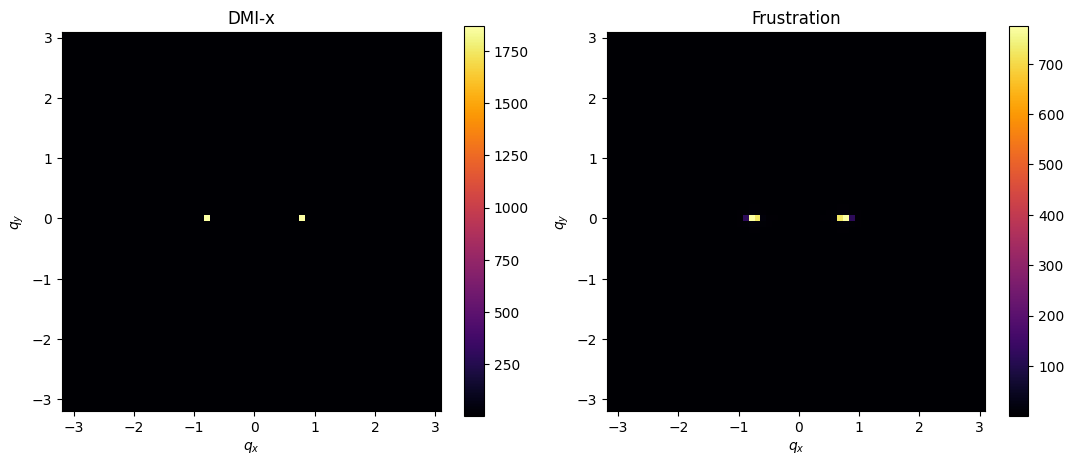

In [20]:

spins_frustration = np.load(
    "spins_frustration_latest.npy"
)

qx_f, qy_f, S_q_f = static_structure_factor(spins_frustration)

S_peak_f = S_q_f.copy()
S_peak_f[len(qx_f)//2, len(qy_f)//2] = 0

i_f, j_f = np.unravel_index(np.argmax(S_peak_f), S_peak_f.shape)

print("DMI-x:", qx[i], qy[j])
print("Frustration:", qx_f[i_f], qy_f[j_f])

print("Difference in |qx|:", abs(abs(qx[i]) - abs(qx_f[i_f])))
print("Difference in |qy|:", abs(abs(qy[j]) - abs(qy_f[j_f])))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, model, qx_plot, qy_plot, sq in [
    (axes[0], "DMI-x", qx, qy, S_q),
    (axes[1], "Frustration", qx_f, qy_f, S_q_f)
]:
    im = ax.pcolormesh(qx_plot, qy_plot, sq.T, shading="auto", cmap="inferno")
    ax.set_title(model)
    ax.set_xlabel(r"$q_x$")
    ax.set_ylabel(r"$q_y$")
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


In [21]:

def spin_chirality(spins):
    spin_x = np.roll(spins, -1, axis=1)
    spin_y = np.roll(spins, -1, axis=2)

    chi_x = np.mean(np.cross(spins, spin_x), axis=(1, 2))
    chi_y = np.mean(np.cross(spins, spin_y), axis=(1, 2))

    return chi_x, chi_y


chi_x_dmi, chi_y_dmi = spin_chirality(spins_dmi)
chi_x_fr, chi_y_fr = spin_chirality(spins_frustration)

for model, cx, cy in [
    ("DMI-x", chi_x_dmi, chi_y_dmi),
    ("Frustration", chi_x_fr, chi_y_fr)
]:
    print(f"\n{model}")
    print("Mean chirality x:", np.mean(cx, axis=0))
    print("Mean chirality y:", np.mean(cy, axis=0))
    print("Mean |chirality x|:", np.mean(np.linalg.norm(cx, axis=1)))
    print("Mean |chirality y|:", np.mean(np.linalg.norm(cy, axis=1)))
    print("Mean signed x chirality:", np.mean(cx[:, 0]))



DMI-x
Mean chirality x: [6.7372674e-01 1.2987264e-03 6.6808960e-04]
Mean chirality y: [ 1.8096162e-05 -3.3742308e-05 -1.9201605e-05]
Mean |chirality x|: 0.6737526
Mean |chirality y|: 0.00059748435
Mean signed x chirality: 0.6737268

Frustration
Mean chirality x: [-0.00133477 -0.03306834 -0.04048856]
Mean chirality y: [2.5455395e-04 8.3813517e-05 2.1199487e-05]
Mean |chirality x|: 0.2698524
Mean |chirality y|: 0.0018208565
Mean signed x chirality: -0.0013347734


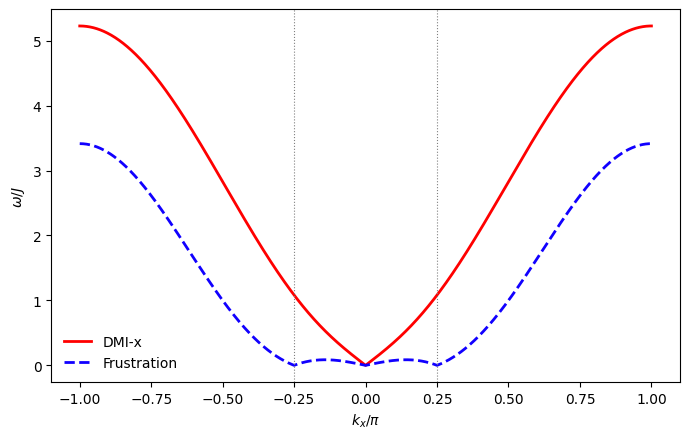

DMI-x omega(q0): 1.0823922002923945
Frustration omega(q0): 0.0


In [23]:

import numpy as np
import matplotlib.pyplot as plt

J_lswt = 1.0
q0_lswt = np.pi / 4
D_lswt = J_lswt * np.tan(q0_lswt)
J2_lswt = J_lswt / (4 * np.cos(q0_lswt))

k_lswt = np.linspace(-np.pi, np.pi, 1001)

lambda_dmi = 2 * J_lswt * (1 + np.cos(q0_lswt)) + 2 * D_lswt * np.sin(q0_lswt)

A_dmi = lambda_dmi - 2 * J_lswt * (np.cos(k_lswt) + 1)

B_dmi = lambda_dmi - 2 * (
    (J_lswt * np.cos(q0_lswt) + D_lswt * np.sin(q0_lswt)) * np.cos(k_lswt)
    + J_lswt
)

omega_dmi = np.sqrt(np.maximum(A_dmi * B_dmi, 0))

lambda_fr = 2 * J_lswt * (1 + np.cos(q0_lswt)) - 2 * J2_lswt * np.cos(2 * q0_lswt)

A_fr = lambda_fr - 2 * J_lswt * (np.cos(k_lswt) + 1) + 2 * J2_lswt * np.cos(2 * k_lswt)

B_fr = lambda_fr - 2 * J_lswt * (
    np.cos(q0_lswt) * np.cos(k_lswt) + 1
) + 2 * J2_lswt * np.cos(2 * q0_lswt) * np.cos(2 * k_lswt)

omega_fr = np.sqrt(np.maximum(A_fr * B_fr, 0))

plt.figure(figsize=(7, 4.5))

plt.plot(k_lswt / np.pi, omega_dmi, color="#C00032", lw=2, label="DMI-x")
plt.plot(k_lswt / np.pi, omega_fr, color="#0055CC", lw=2, ls="--", label="Frustration")

plt.axvline(q0_lswt / np.pi, color="gray", lw=0.8, ls=":")
plt.axvline(-q0_lswt / np.pi, color="gray", lw=0.8, ls=":")

plt.xlabel(r"$k_x/\pi$")
plt.ylabel(r"$\omega/J$")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

idx = np.argmin(np.abs(k_lswt - q0_lswt))

print("DMI-x omega(q0):", omega_dmi[idx])
print("Frustration omega(q0):", omega_fr[idx])
